In [15]:
# Block 0 — setup. Code from GitHub onto the VM disk; data + embeddings on Drive.
import os, sys
from google.colab import drive
drive.mount('/content/drive')

REPO_DIR = "/content/NeoAntigen"
try:   # private repo: store a GitHub token as Colab secret GH_TOKEN
    from google.colab import userdata
    TOKEN = userdata.get("GH_TOKEN")
except Exception:
    TOKEN = ""
URL = f"https://{TOKEN + '@' if TOKEN else ''}github.com/Tienanh209/NeoAntigen.git"
if not os.path.exists(REPO_DIR):
    !git clone {URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull --ff-only
%cd {REPO_DIR}
sys.path.insert(0, REPO_DIR)

# numpy/scipy/torch are filtered out: Colab's torch is built against its own numpy
!grep -viE '^(torch|torchvision|torchaudio|nvidia-|numpy|scipy|#)' requirements.txt > req_colab.txt
!pip install -q -r req_colab.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already up to date.
/content/NeoAntigen


In [16]:
# Block 1 — the AUTHORS' dataset, embedding caches, shared settings.
# Every experiment block below depends on THIS cell and on nothing else:
# they communicate only through the results store on Drive.
import pandas as pd
from src import authors, config, data, embed, results, runner

df = authors.load()      # github.com/B1607/DeepNeoAG at a pinned commit, cached on Drive
BID = data.build_id(df)
MAXLEN = data.max_len(df)
SEEDS = (42,)               # single seed: fast, but AUC_std is then NaN and nothing
                            # separates a real effect from run-to-run noise
PLM = "prott5"              # feature set for the hyperparameter sweeps, as in the paper
ESM = "esm2_650m"           # the ESM model used by the ESM baselines
FORCE = False               # True re-runs committed configurations

for plm in ("prott5", "esm2_650m", "esm1b"):
    if embed.is_cached(plm, BID):
        embed.stage(plm, BID)
    else:
        print(f"!! {plm} has no cache for build {BID} — run embeddings.ipynb (CEDAR) or embeddings_authors.ipynb (authors) first")

print("build id:", BID, "| max_len:", MAXLEN, "| results:", config.RESULTS_DIR)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

build id: bdfb2e744c | max_len: 35 | results: /content/drive/MyDrive/s1156052/NeoAntigen/ckpt/results
label     0    1
split           
test   1343   61
train  5367  241


[AU_A_window 1/5] window 8
  seed 42: cv AUC 0.8257 | test AUC 0.9143
[AU_A_window 2/5] window 16
  seed 42: cv AUC 0.8602 | test AUC 0.9314
[AU_A_window 3/5] window 24
  seed 42: cv AUC 0.9132 | test AUC 0.9318
[AU_A_window 4/5] window 32
  seed 42: cv AUC 0.8868 | test AUC 0.9313
[AU_A_window 5/5] window 34
  seed 42: cv AUC 0.9085 | test AUC 0.9237

Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.3934,0.9933,0.9672,0.5204,0.9143,0.5941,0.5106,0.7273,0.9143,NaN
1,window 16,0.7213,0.9732,0.9623,0.6108,0.9314,0.6063,0.6241,0.5500,0.9314,NaN
2,window 24,0.6721,0.9680,0.9551,0.5502,0.9318,0.5433,0.5655,0.4881,0.9318,NaN
3,window 32,0.5574,0.9836,0.9651,0.5636,0.9313,0.6183,0.5812,0.6071,0.9313,NaN
4,window 34,0.5082,0.9896,0.9687,0.5761,0.9237,0.5956,0.5849,0.6889,0.9237,NaN
5,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


5-fold cross-validation


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.3610,0.9920,0.9649,0.4757,0.8257,0.4645,0.4690,0.6692,0.8257,NaN
1,window 16,0.5643,0.9655,0.9483,0.4626,0.8602,0.4511,0.4840,0.4237,0.8602,NaN
2,window 24,0.6307,0.9659,0.9515,0.5105,0.9132,0.4879,0.5278,0.4537,0.9132,NaN
3,window 32,0.5519,0.9834,0.9649,0.5567,0.8868,0.5082,0.5745,0.5991,0.8868,NaN
4,window 34,0.5062,0.9894,0.9686,0.5718,0.9085,0.5672,0.5810,0.6816,0.9085,NaN
5,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


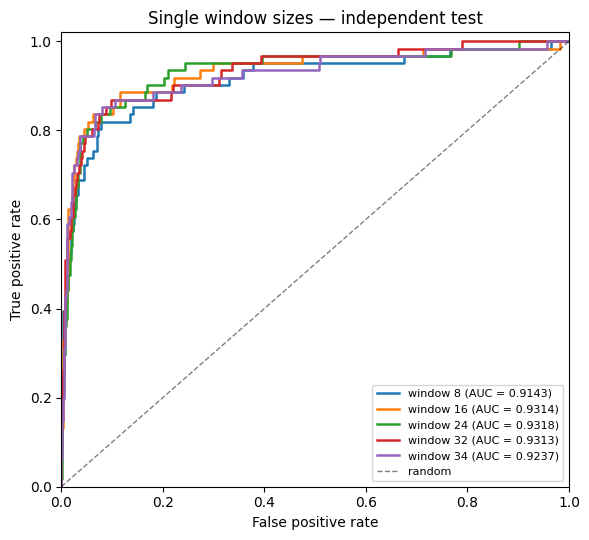

In [9]:
# Block 2 — Experiment A: single window sizes (paper Table 2)
cfgs = [dict(label=f"window {w}", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": [w], "filters": 512})
        for w in (8, 16, 24, 32, 34)]
runner.run_series("AU_A_window", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("\nIndependent test")
display(results.fmt(results.table("AU_A_window")))
print("5-fold cross-validation")
display(results.fmt(results.table("AU_A_window", eval_split="cv")))
results.roc("AU_A_window", title="Single window sizes — independent test");

[AU_B_combo 1/5] [34]
  seed 42: cv AUC 0.9085 | test AUC 0.9237
[AU_B_combo 2/5] [34, 32]
  seed 42: cv AUC 0.9014 | test AUC 0.9280
[AU_B_combo 3/5] [34, 32, 24]
  seed 42: cv AUC 0.8868 | test AUC 0.9361
[AU_B_combo 4/5] [34, 32, 24, 16]
  seed 42: cv AUC 0.8858 | test AUC 0.9185
[AU_B_combo 5/5] [34, 32, 24, 16, 8]
  seed 42: cv AUC 0.8772 | test AUC 0.9184


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.5082,0.9896,0.9687,0.5761,0.9237,0.5956,0.5849,0.6889,0.9237,NaN
1,"[34, 32]",0.6393,0.9799,0.9651,0.5964,0.9280,0.5972,0.6142,0.5909,0.9280,NaN
2,"[34, 32, 24]",0.7377,0.9695,0.9594,0.6012,0.9361,0.5734,0.6122,0.5233,0.9361,NaN
3,"[34, 32, 24, 16]",0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
4,"[34, 32, 24, 16, 8]",0.6230,0.9762,0.9608,0.5612,0.9184,0.5699,0.5802,0.5429,0.9184,NaN
5,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.5062,0.9894,0.9686,0.5718,0.9085,0.5672,0.5810,0.6816,0.9085,NaN
1,"[34, 32]",0.5685,0.9767,0.9592,0.5239,0.9014,0.5382,0.5447,0.5229,0.9014,NaN
2,"[34, 32, 24]",0.6349,0.9642,0.9501,0.5056,0.8868,0.4461,0.5222,0.4435,0.8868,NaN
3,"[34, 32, 24, 16]",0.5519,0.9730,0.9549,0.4904,0.8858,0.4350,0.5125,0.4784,0.8858,NaN
4,"[34, 32, 24, 16, 8]",0.5809,0.9739,0.9570,0.5166,0.8772,0.4420,0.5374,0.5000,0.8772,NaN
5,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


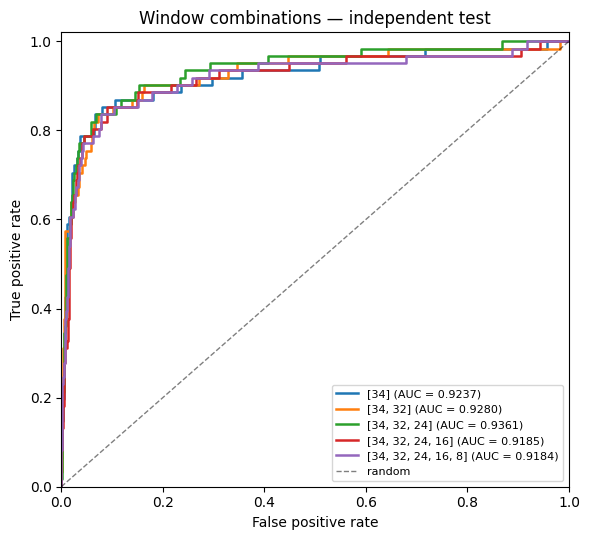

In [10]:
# Block 3 — Experiment B: window combinations (paper Table 3)
combos = [[34], [34, 32], [34, 32, 24], [34, 32, 24, 16], [34, 32, 24, 16, 8]]
cfgs = [dict(label=str(c), features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": c, "filters": 512}) for c in combos]
runner.run_series("AU_B_combo", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_B_combo")))
display(results.fmt(results.table("AU_B_combo", eval_split="cv")))
results.roc("AU_B_combo", title="Window combinations — independent test");

[AU_C_filters 1/5] 128 filters
  [skip] 128 filters — already committed
[AU_C_filters 2/5] 256 filters
  [skip] 256 filters — already committed
[AU_C_filters 3/5] 512 filters
  [skip] 512 filters — already committed
[AU_C_filters 4/5] 1024 filters
  [skip] 1024 filters — already committed
[AU_C_filters 5/5] 2048 filters
  [skip] 2048 filters — already committed


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std,conv_params
0,128 filters,0.6066,0.9814,0.9651,0.5834,0.9324,0.5876,0.6016,0.5968,0.9324,NaN,13894144.0
1,256 filters,0.7049,0.9754,0.9637,0.6130,0.9348,0.6009,0.6277,0.5658,0.9348,NaN,27788288.0
2,512 filters,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN,55576576.0
3,1024 filters,0.8197,0.9114,0.9074,0.4580,0.9311,0.6126,0.4348,0.2959,0.9311,NaN,111153152.0
4,2048 filters,0.6393,0.9792,0.9644,0.5915,0.9341,0.5770,0.6094,0.5821,0.9341,NaN,222306304.0
5,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN,NaN


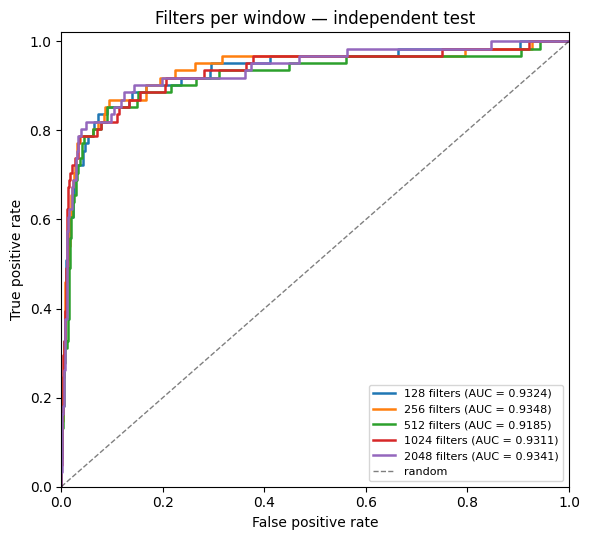

In [9]:
# Block 4 — Experiment C: filters per window (paper Table 4)
# Only the filter count changes: dropout, hidden width and batch size stay at their
# defaults, so differences are due to filters alone. conv_params is in the table on
# purpose: at 2048 filters the convolutions hold ~200-300M parameters for ~1.1k
# training peptides, which is the point of this sweep.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"{f} filters", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": f})
        for f in (128, 256, 512, 1024, 2048)]
runner.run_series("AU_C_filters", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_C_filters", extra_cols=("conv_params",))))
results.roc("AU_C_filters", title="Filters per window — independent test");

[AU_J_hidden 1/6] 32 hidden
  [skip] 32 hidden — already committed
[AU_J_hidden 2/6] 64 hidden
  [skip] 64 hidden — already committed
[AU_J_hidden 3/6] 128 hidden
  [skip] 128 hidden — already committed
[AU_J_hidden 4/6] 256 hidden
  [skip] 256 hidden — already committed
[AU_J_hidden 5/6] 512 hidden
  [skip] 512 hidden — already committed
[AU_J_hidden 6/6] 1024 hidden
  [skip] 1024 hidden — already committed


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,32 hidden,0.4754,0.9859,0.9637,0.5175,0.9228,0.4910,0.5321,0.6042,0.9228,NaN
1,64 hidden,0.7213,0.9665,0.9558,0.5755,0.9172,0.5732,0.5867,0.4944,0.9172,NaN
2,128 hidden,0.6230,0.9829,0.9672,0.6058,0.9192,0.5954,0.6230,0.6230,0.9192,NaN
3,256 hidden,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
4,512 hidden,0.5574,0.9873,0.9687,0.5935,0.9372,0.6217,0.6071,0.6667,0.9372,NaN
5,1024 hidden,0.7213,0.9650,0.9544,0.5683,0.9268,0.5919,0.5789,0.4835,0.9268,NaN
6,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,32 hidden,0.2614,0.9857,0.9545,0.3211,0.7116,0.1837,0.3307,0.4500,0.7116,NaN
1,64 hidden,0.6556,0.9629,0.9497,0.5138,0.8624,0.4749,0.5284,0.4426,0.8624,NaN
2,128 hidden,0.5145,0.9775,0.9576,0.4881,0.8589,0.3753,0.5103,0.5061,0.8589,NaN
3,256 hidden,0.5519,0.9730,0.9549,0.4904,0.8858,0.4350,0.5125,0.4784,0.8858,NaN
4,512 hidden,0.5270,0.9860,0.9663,0.5583,0.9017,0.5341,0.5734,0.6287,0.9017,NaN
5,1024 hidden,0.6390,0.9607,0.9469,0.4930,0.8948,0.4677,0.5083,0.4219,0.8948,NaN
6,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


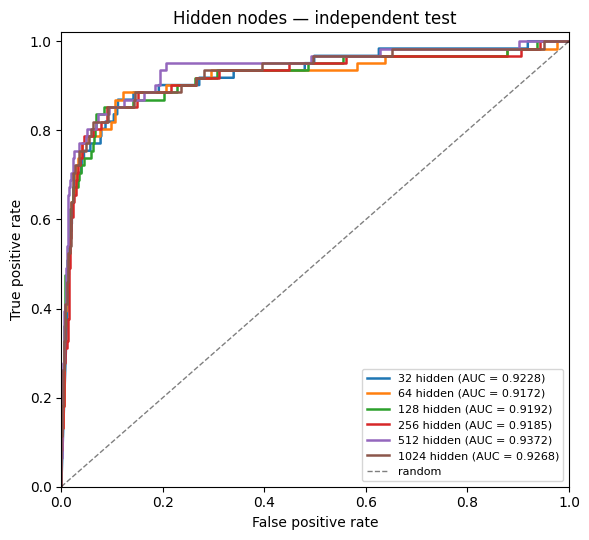

In [13]:
# Block 5 — Experiment J: hidden nodes (width of the fully connected layer)
# Only the hidden width changes; windows, filters and dropout stay at the defaults.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"{h} hidden", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": 512, "hidden": h})
        for h in (32, 64, 128, 256, 512, 1024)]
runner.run_series("AU_J_hidden", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_J_hidden")))
display(results.fmt(results.table("AU_J_hidden", eval_split="cv")))
results.roc("AU_J_hidden", title="Hidden nodes — independent test");

[AU_K_dropout 1/5] dropout 0.0
  [skip] dropout 0.0 — already committed
[AU_K_dropout 2/5] dropout 0.1
  [skip] dropout 0.1 — already committed
[AU_K_dropout 3/5] dropout 0.3
  [skip] dropout 0.3 — already committed
[AU_K_dropout 4/5] dropout 0.5
  [skip] dropout 0.5 — already committed
[AU_K_dropout 5/5] dropout 0.7
  [skip] dropout 0.7 — already committed


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,dropout 0.0,0.5246,0.9911,0.9708,0.6033,0.9383,0.6020,0.6095,0.7273,0.9383,NaN
1,dropout 0.1,0.5410,0.9829,0.9637,0.5457,0.9304,0.5798,0.5641,0.5893,0.9304,NaN
2,dropout 0.3,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
3,dropout 0.5,0.6885,0.9643,0.9523,0.5433,0.9248,0.5435,0.5563,0.4667,0.9248,NaN
4,dropout 0.7,0.5246,0.9873,0.9672,0.5687,0.9313,0.5802,0.5818,0.6531,0.9313,NaN
5,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,dropout 0.0,0.4938,0.9898,0.9684,0.5655,0.8738,0.5653,0.5735,0.6839,0.8738,NaN
1,dropout 0.1,0.5187,0.9816,0.9617,0.5180,0.9092,0.5080,0.5376,0.5580,0.9092,NaN
2,dropout 0.3,0.5519,0.9730,0.9549,0.4904,0.8858,0.4350,0.5125,0.4784,0.8858,NaN
3,dropout 0.5,0.6763,0.9637,0.9513,0.5309,0.8888,0.5131,0.5442,0.4553,0.8888,NaN
4,dropout 0.7,0.5187,0.9866,0.9665,0.5566,0.9154,0.5647,0.5708,0.6345,0.9154,NaN
5,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


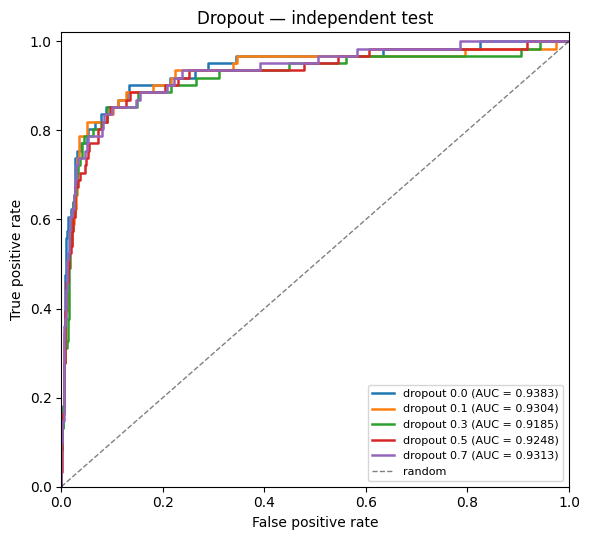

In [17]:
# Block 6 — Experiment K: dropout (applied before and after the hidden layer)
# Only the dropout rate changes. Watch cv vs test: with ~100 training positives, too
# little dropout shows up as a good cv score that does not carry over to test.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"dropout {p}", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": 512, "dropout": p})
        for p in (0.0, 0.1, 0.3, 0.5, 0.7)]
runner.run_series("AU_K_dropout", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_K_dropout")))
display(results.fmt(results.table("AU_K_dropout", eval_split="cv")))
results.roc("AU_K_dropout", title="Dropout — independent test");

[AU_D_plm 1/3] ProtTrans
  [skip] ProtTrans — already committed
[AU_D_plm 2/3] ESM-2
  [skip] ESM-2 — already committed
[AU_D_plm 3/3] ESM-1b
  [skip] ESM-1b — already committed
Cross-validation (5 folds)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.5519,0.9730,0.9549,0.4904,0.8858,0.4350,0.5125,0.4784,0.8858,NaN
1,ESM-2,0.7261,0.9473,0.9378,0.4987,0.9174,0.5231,0.5007,0.3821,0.9174,NaN
2,ESM-1b,0.5560,0.9646,0.9470,0.4525,0.9020,0.4635,0.4743,0.4136,0.9020,NaN
3,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
1,ESM-2,0.7541,0.9486,0.9402,0.5224,0.9262,0.6303,0.5227,0.4000,0.9262,NaN
2,ESM-1b,0.6885,0.9710,0.9587,0.5766,0.9211,0.6272,0.5915,0.5185,0.9211,NaN
3,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


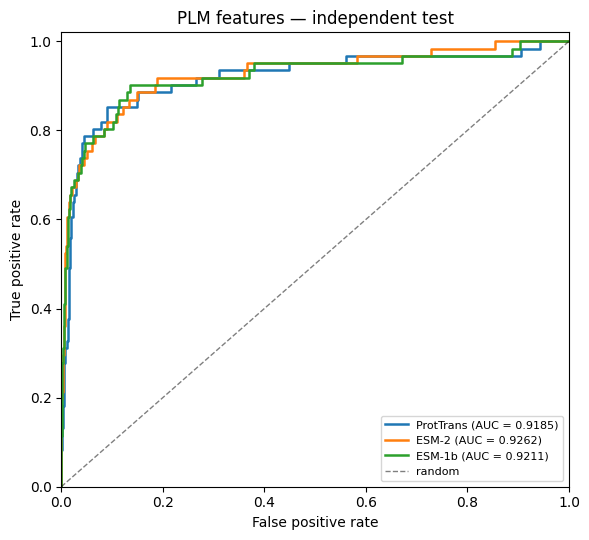

In [ ]:
# Block 7 — Experiment D: pre-trained language model features (paper Table 5, Fig 4a)
BEST_WINDOWS, BEST_FILTERS = [34, 32, 24, 16], 512
cfgs = [dict(label=name, features={"kind": "plm", "plm": plm},
             model={"kind": "mcnn", "windows": BEST_WINDOWS, "filters": BEST_FILTERS})
        for plm, name in [("prott5", "ProtTrans"), ("esm2_650m", "ESM-2"), ("esm1b", "ESM-1b")]]
runner.run_series("AU_D_plm", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation (5 folds)")
display(results.fmt(results.table("AU_D_plm", eval_split="cv")))
print("Independent test")
display(results.fmt(results.table("AU_D_plm")))
results.roc("AU_D_plm", title="PLM features — independent test");

In [ ]:
# Block 8 — Experiment E: classifiers (paper Table 6, Fig 4b)
# KNN / RF / SVM take the mean-pooled embedding; the mCNN keeps per-residue input.
cfgs = [dict(label=n.upper(), features={"kind": "plm_pooled", "plm": PLM},
             model={"kind": "sklearn", "name": n}) for n in ("knn", "rf", "svm")]
cfgs.append(dict(label="mCNN", features={"kind": "plm", "plm": PLM},
                 model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512}))
runner.run_series("AU_E_clf", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_E_clf")))
results.roc("AU_E_clf", title="Classifiers — independent test");

[AU_E_clf 1/4] KNN
  seed 42: cv AUC 0.7949 | test AUC 0.8746
[AU_E_clf 2/4] RF
  seed 42: cv AUC 0.8875 | test AUC 0.8970
[AU_E_clf 3/4] SVM
  seed 42: cv AUC 0.8849 | test AUC 0.9149
[AU_E_clf 4/4] mCNN


In [4]:
# Block 9 — Experiment F: length confound (replaces the paper's MHC-I / MHC-II table)
# This dataset carries no MHC annotation, and a length rule puts only a handful of the
# 61 test positives in the 8-11 aa range, so that table cannot be rebuilt here. More
# important is what the length distribution shows: no peptide is shorter than 11 aa
# (consistent with CD-HIT's default -l 10, which drops them) and positives are much
# longer than negatives. If length alone separates the classes, a good AUC from a
# sequence model proves much less than it appears to.
print(df.groupby(["split", "label"])["length"].describe()[["count", "mean", "min", "50%", "max"]].round(1))

cfgs = [dict(label="length only (LogReg)", features={"kind": "length"},
             model={"kind": "sklearn", "name": "logreg"})]
runner.run_series("AU_F_length", cfgs, df=df, seeds=SEEDS, force=FORCE)
display(results.fmt(results.table("AU_F_length")))
display(results.fmt(results.table("AU_F_length", eval_split="cv")))

              count  mean   min   50%   max
split label                                
test  0      1343.0  12.7  11.0  12.0  35.0
      1        61.0  21.3  11.0  24.0  31.0
train 0      5367.0  12.7  11.0  12.0  33.0
      1       241.0  19.2  11.0  16.0  31.0
[AU_F_length 1/1] length only (LogReg)
  seed 42: cv AUC 0.8567 | test AUC 0.8899


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,length only (LogReg),0.4262,0.9963,0.9715,0.5862,0.8899,0.5188,0.5652,0.8387,0.8899,NaN
1,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,length only (LogReg),0.3568,0.9963,0.9688,0.5259,0.8567,0.3812,0.4957,0.8113,0.8567,NaN
1,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


[AU_G_baselines 1/6] length only (LogReg)
  seed 42: cv AUC 0.8567 | test AUC 0.8899
[AU_G_baselines 2/6] Amino acid + LogReg
  seed 42: cv AUC 0.7284 | test AUC 0.6630
[AU_G_baselines 3/6] One-hot + mCNN
  seed 42: cv AUC 0.5387 | test AUC 0.5760
[AU_G_baselines 4/6] ESM + LogReg
  seed 42: cv AUC 0.8479 | test AUC 0.8554
[AU_G_baselines 5/6] ESM + CNN
  seed 42: cv AUC 0.9135 | test AUC 0.9416
[AU_G_baselines 6/6] ESM + mCNN
  seed 42: cv AUC 0.9174 | test AUC 0.9262


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,length only (LogReg),0.4262,0.9963,0.9715,0.5862,0.8899,0.5188,0.5652,0.8387,0.8899,NaN
1,Amino acid + LogReg,0.4426,0.7461,0.7329,0.0875,0.6630,0.0715,0.1259,0.0734,0.6630,NaN
2,One-hot + mCNN,0.0820,0.9926,0.9530,0.1478,0.5760,0.1163,0.1316,0.3333,0.5760,NaN
3,ESM + LogReg,0.4262,0.9739,0.9501,0.4002,0.8554,0.3421,0.4262,0.4262,0.8554,NaN
4,ESM + CNN,0.6885,0.9732,0.9608,0.5889,0.9416,0.5739,0.6043,0.5385,0.9416,NaN
5,ESM + mCNN,0.7541,0.9486,0.9402,0.5224,0.9262,0.6303,0.5227,0.4000,0.9262,NaN
6,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


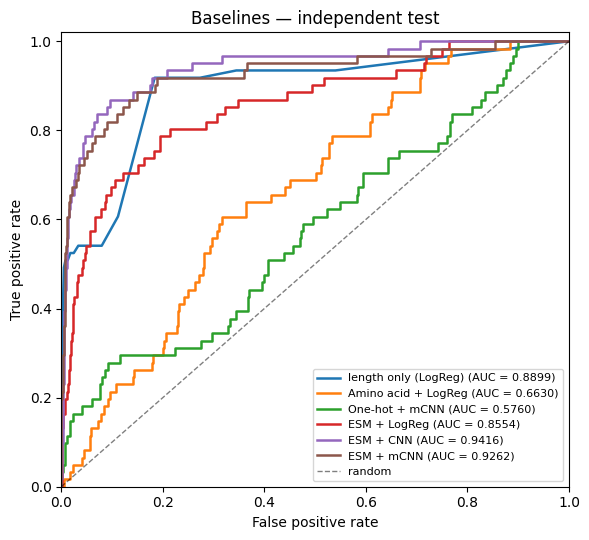

In [5]:
# Block 10 — Experiment G: baselines
# Composition alone -> order (one-hot mCNN) -> pretraining (ESM + LogReg) -> local
# scanning on top of pretraining (ESM + CNN, ESM + mCNN). All three ESM rows share the
# same ESM-2 embeddings, so the gaps isolate what pooling, one window and several
# windows add. "length only" is a control: if peptide length alone separates the
# classes, a good AUC from a sequence model proves much less than it appears to.
WINDOWS = [34, 32, 24, 16]
cfgs = [
    dict(label="length only (LogReg)", features={"kind": "length"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="Amino acid + LogReg", features={"kind": "aac"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="One-hot + mCNN", features={"kind": "onehot"},
         model={"kind": "mcnn", "windows": WINDOWS, "filters": 512}),
    dict(label="ESM + LogReg", features={"kind": "plm_pooled", "plm": ESM},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="ESM + CNN", features={"kind": "plm", "plm": ESM},
         model={"kind": "mcnn", "windows": [34], "filters": 512}),
    dict(label="ESM + mCNN", features={"kind": "plm", "plm": ESM},
         model={"kind": "mcnn", "windows": WINDOWS, "filters": 512}),
]
runner.run_series("AU_G_baselines", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("AU_G_baselines")))
results.roc("AU_G_baselines", title="Baselines — independent test");

In [6]:
# Block 11 — Experiment H: class weighting (CS535 E7)
# At ~1 positive per 13 negatives, this is what moves sensitivity against precision.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="weighted BCE", train_cfg={"class_weight": True}, **base),
        dict(label="unweighted BCE", train_cfg={"class_weight": False}, **base)]
runner.run_series("AU_H_weight", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Tuned threshold (chosen on CV)")
display(results.fmt(results.table("AU_H_weight")))
print("Fixed 0.5 threshold — note how differently 0.5 behaves between the two")
display(results.fmt(results.table("AU_H_weight", thr_mode="fixed")))

[AU_H_weight 1/2] weighted BCE
  seed 42: cv AUC 0.8858 | test AUC 0.9185
[AU_H_weight 2/2] unweighted BCE
  seed 42: cv AUC 0.8999 | test AUC 0.9182
Tuned threshold (chosen on CV)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
1,unweighted BCE,0.5246,0.9836,0.9637,0.5387,0.9182,0.6026,0.5565,0.5926,0.9182,NaN
2,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


Fixed 0.5 threshold — note how differently 0.5 behaves between the two


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.6066,0.9777,0.9615,0.5587,0.9185,0.5453,0.5781,0.5522,0.9185,NaN
1,unweighted BCE,0.2459,0.9963,0.9637,0.4166,0.9182,0.6026,0.3704,0.7500,0.9182,NaN
2,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


In [7]:
# Block 12 — Experiment I: similarity leakage (CS535 E8)
# Random folds let near-duplicate peptides sit on both sides of the split;
# grouped folds keep peptides that share an 8-mer together.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="random folds", split_mode="stratified", **base),
        dict(label="similarity-controlled folds", split_mode="grouped", **base)]
runner.run_series("AU_I_leak", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation — the leakage shows up here, not on the test split")
display(results.fmt(results.table("AU_I_leak", eval_split="cv")))
display(results.fmt(results.table("AU_I_leak")))

g = data.kmer_groups(df)
print(f"\n{len(df)} peptides fall into {g.nunique()} shared-8-mer groups; "
      f"largest group has {g.value_counts().iloc[0]}")

[AU_I_leak 1/2] random folds
  seed 42: cv AUC 0.8858 | test AUC 0.9185
[AU_I_leak 2/2] similarity-controlled folds
  seed 42: cv AUC 0.8934 | test AUC 0.9291
Cross-validation — the leakage shows up here, not on the test split


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.5519,0.9730,0.9549,0.4904,0.8858,0.4350,0.5125,0.4784,0.8858,NaN
1,similarity-controlled folds,0.7386,0.9301,0.9219,0.4549,0.8934,0.4129,0.4484,0.3219,0.8934,NaN
2,all-negative baseline,0.0000,1.0000,0.9570,0.0000,0.5000,0.0430,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
1,similarity-controlled folds,0.8033,0.9337,0.9281,0.5047,0.9291,0.5732,0.4925,0.3551,0.9291,NaN
2,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN



7012 peptides fall into 5269 shared-8-mer groups; largest group has 71


--- Baselines (AU_G_baselines) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,length only (LogReg),0.4262,0.9963,0.9715,0.5862,0.8899,0.5188,0.5652,0.8387,0.8899,NaN
1,Amino acid + LogReg,0.4426,0.7461,0.7329,0.0875,0.6630,0.0715,0.1259,0.0734,0.6630,NaN
2,One-hot + mCNN,0.0820,0.9926,0.9530,0.1478,0.5760,0.1163,0.1316,0.3333,0.5760,NaN
3,ESM + LogReg,0.4262,0.9739,0.9501,0.4002,0.8554,0.3421,0.4262,0.4262,0.8554,NaN
4,ESM + CNN,0.6885,0.9732,0.9608,0.5889,0.9416,0.5739,0.6043,0.5385,0.9416,NaN
5,ESM + mCNN,0.7541,0.9486,0.9402,0.5224,0.9262,0.6303,0.5227,0.4000,0.9262,NaN
6,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


--- Length-only control (AU_F_length) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,length only (LogReg),0.4262,0.9963,0.9715,0.5862,0.8899,0.5188,0.5652,0.8387,0.8899,NaN
1,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


--- Classifiers: not run yet

--- PLM features: not run yet

--- Single window sizes (AU_A_window) — independent test


...

--- Class weighting (AU_H_weight) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
1,unweighted BCE,0.5246,0.9836,0.9637,0.5387,0.9182,0.6026,0.5565,0.5926,0.9182,NaN
2,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN


--- Similarity leakage (AU_I_leak) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.6230,0.9762,0.9608,0.5612,0.9185,0.5453,0.5802,0.5429,0.9185,NaN
1,similarity-controlled folds,0.8033,0.9337,0.9281,0.5047,0.9291,0.5732,0.4925,0.3551,0.9291,NaN
2,all-negative baseline,0.0000,1.0000,0.9566,0.0000,0.5000,0.0434,0.0000,0.0000,NaN,NaN



37 committed runs in /content/drive/MyDrive/s1156052/NeoAntigen/ckpt/results


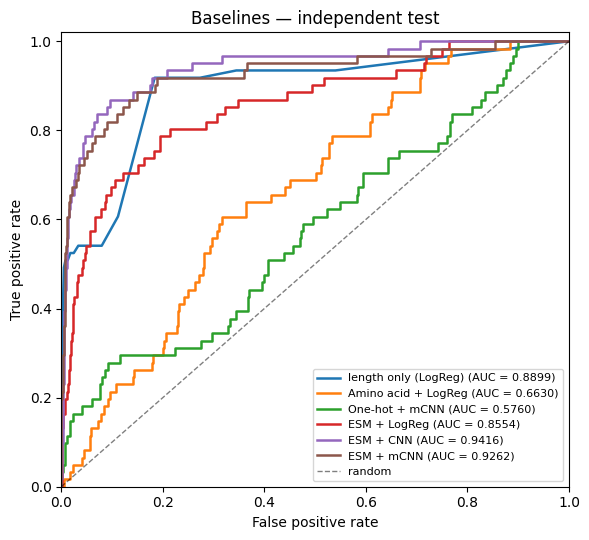

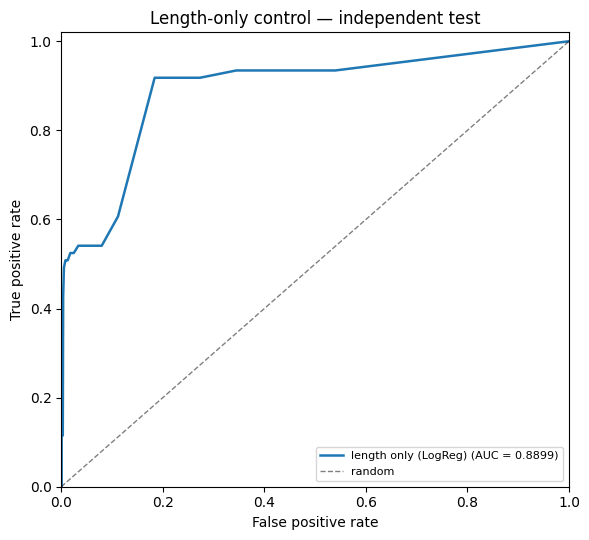

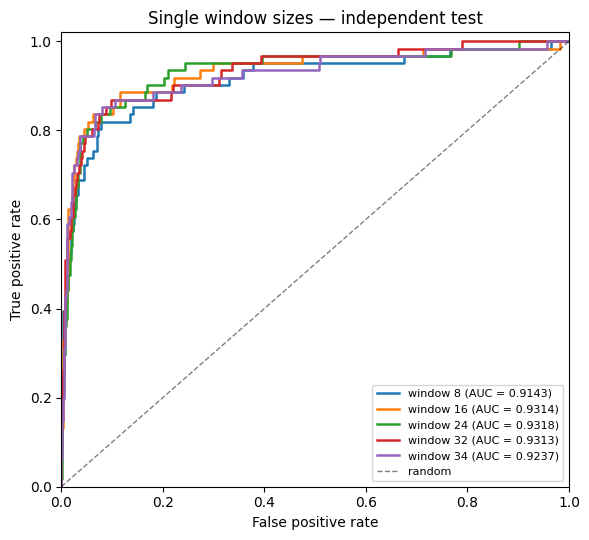

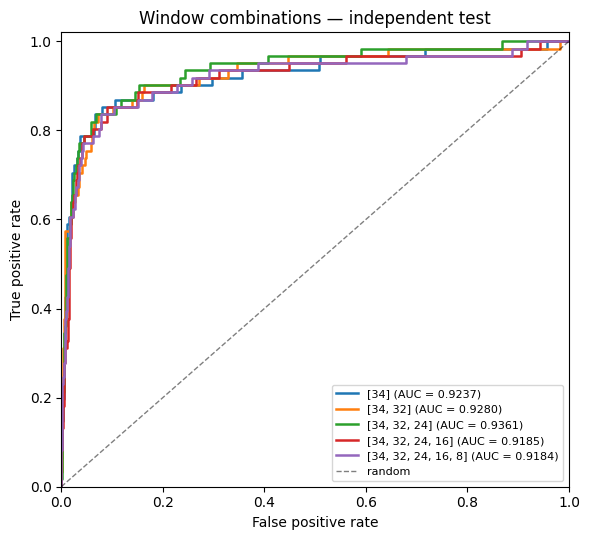

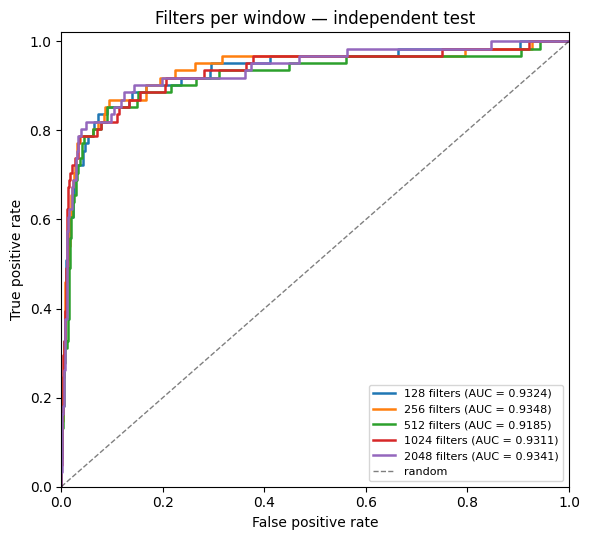

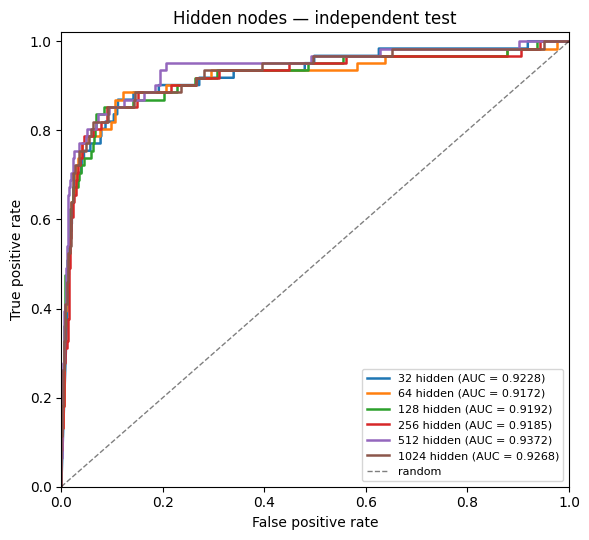

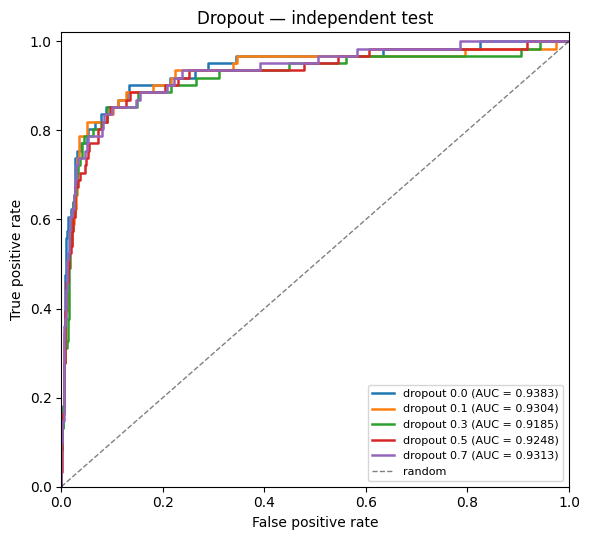

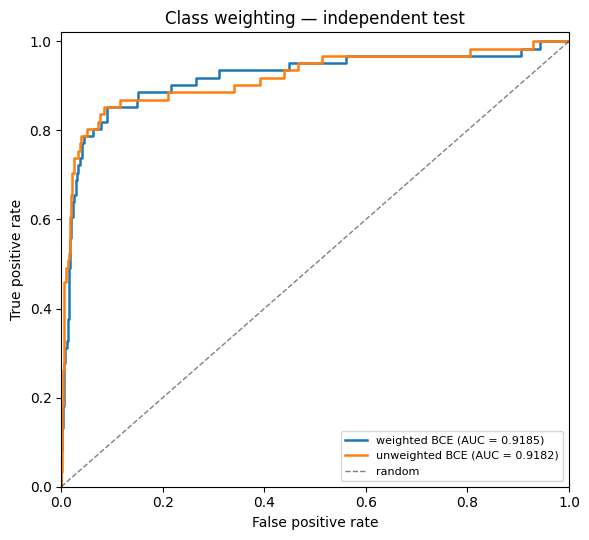

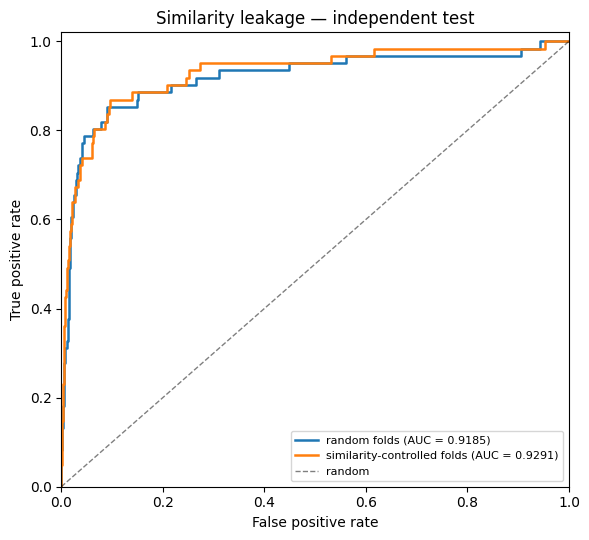

In [18]:
# Block 13 — report: every table and figure, rebuilt from the store. No training.
# This is what to run after a disconnect to see the whole state of the project.
TITLES = {"AU_G_baselines": "Baselines", "AU_F_length": "Length-only control", "AU_E_clf": "Classifiers", "AU_D_plm": "PLM features",
          "AU_A_window": "Single window sizes", "AU_B_combo": "Window combinations",
          "AU_C_filters": "Filters per window", "AU_J_hidden": "Hidden nodes", "AU_K_dropout": "Dropout",
          "AU_H_weight": "Class weighting", "AU_I_leak": "Similarity leakage"}

for exp_id, title in TITLES.items():
    t = results.table(exp_id)
    if t.empty:
        print(f"--- {title}: not run yet\n")
        continue
    print(f"--- {title} ({exp_id}) — independent test")
    display(results.fmt(t))
    results.roc(exp_id, title=f"{title} — independent test")

runs = results.load_runs()
print(f"\n{len(runs)} committed runs in {config.RESULTS_DIR}")